In [1]:
!pip install networkx plotly matplotlib

In [2]:
import pandas as pd
import numpy as np
import networkx as nx
from networkx.algorithms import bipartite
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# ── CONFIG ────────────────────────────────────────────────────────────────
PAIRS_CSV      = "email_reply_pairs.csv"
EMB_DIR        = "embeddings"
GRAPH_SAMPLE   = 300      # nodes to visualize (full 48k = unreadable)
SIM_THRESHOLD  = 0.30     # minimum cosine sim to draw an edge
TOP_K_EDGES    = 3        # each email node connects to top-K reply nodes
# ──────────────────────────────────────────────────────────────────────────

df          = pd.read_csv(PAIRS_CSV)
email_sbert = np.load(f"{EMB_DIR}/email_sbert.npy")
reply_sbert = np.load(f"{EMB_DIR}/reply_sbert.npy")

print(f"Pairs loaded        : {len(df):,}")
print(f"email_sbert shape   : {email_sbert.shape}")
print(f"reply_sbert shape   : {reply_sbert.shape}")

Pairs loaded        : 48,184
email_sbert shape   : (48184, 384)
reply_sbert shape   : (48184, 384)


In [3]:
print("Building bipartite graph...")

G = nx.Graph()

# ── Add nodes ─────────────────────────────────────────────
# Left partition  = email nodes  (prefix "E_")
# Right partition = reply nodes  (prefix "R_")
for i in range(len(df)):
    G.add_node(f"E_{i}", 
               bipartite=0,          # left partition
               label="email",
               subject=str(df['subject'].iloc[i])[:40],
               wc=int(df['email_wc'].iloc[i]))

    G.add_node(f"R_{i}", 
               bipartite=1,          # right partition
               label="reply",
               subject=str(df['subject'].iloc[i])[:40],
               wc=int(df['reply_wc'].iloc[i]))

# ── Add edges with cosine similarity as weight ────────────
# For each email, connect to its TRUE reply + any high-sim replies
# (this creates a richer graph than just 1-1 pairs)

print("Computing edge weights (cosine similarities)...")
edge_count = 0

# Batch cosine sim: email i vs reply i (true pairs)
true_sims = np.sum(email_sbert * reply_sbert, axis=1)  # dot product = cosine (L2 normed)

for i in range(len(df)):
    sim = float(true_sims[i])
    if sim >= SIM_THRESHOLD:
        G.add_edge(f"E_{i}", f"R_{i}", weight=sim, edge_type="true_pair")
        edge_count += 1

print(f"  True-pair edges added    : {edge_count:,}")
print(f"  Edges below threshold    : {len(df) - edge_count:,}")

# ── Graph stats ───────────────────────────────────────────
email_nodes = [n for n, d in G.nodes(data=True) if d.get('bipartite') == 0]
reply_nodes = [n for n, d in G.nodes(data=True) if d.get('bipartite') == 1]

print(f"\n{'='*50}")
print(f"   BIPARTITE GRAPH STATISTICS")
print(f"{'='*50}")
print(f"  Email nodes (left)   : {len(email_nodes):,}")
print(f"  Reply nodes (right)  : {len(reply_nodes):,}")
print(f"  Edges                : {G.number_of_edges():,}")
print(f"  Density              : {nx.density(G):.6f}")
print(f"  Avg degree           : {np.mean([d for _,d in G.degree()]):.2f}")
print(f"  Is bipartite         : {bipartite.is_bipartite(G)}")
print(f"{'='*50}")

Building bipartite graph...
Computing edge weights (cosine similarities)...
  True-pair edges added    : 29,321
  Edges below threshold    : 18,863

   BIPARTITE GRAPH STATISTICS
  Email nodes (left)   : 48,184
  Reply nodes (right)  : 48,184
  Edges                : 29,321
  Density              : 0.000006
  Avg degree           : 0.61
  Is bipartite         : True


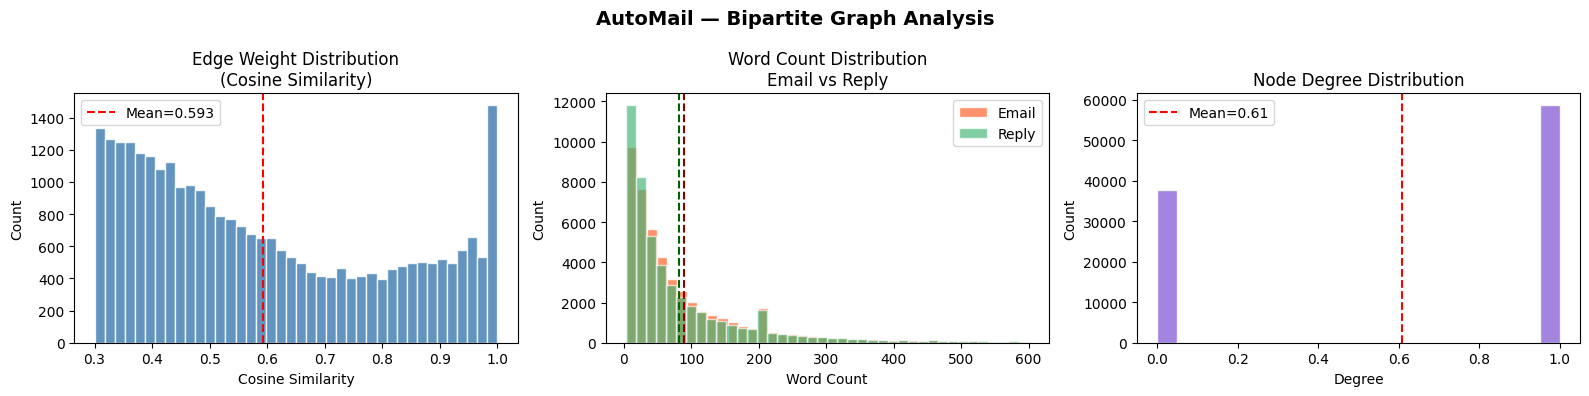

✅ Analysis plot saved → bipartite_analysis.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("AutoMail — Bipartite Graph Analysis", fontsize=14, fontweight='bold')

# ── Plot 1: Edge weight (cosine sim) distribution ────────
weights = [d['weight'] for _,_,d in G.edges(data=True)]
axes[0].hist(weights, bins=40, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(weights), color='red', linestyle='--', linewidth=1.5,
                label=f'Mean={np.mean(weights):.3f}')
axes[0].set_title("Edge Weight Distribution\n(Cosine Similarity)")
axes[0].set_xlabel("Cosine Similarity")
axes[0].set_ylabel("Count")
axes[0].legend()

# ── Plot 2: Email word count distribution ─────────────────
axes[1].hist(df['email_wc'], bins=40, color='coral', edgecolor='white', alpha=0.85,
             label='Email')
axes[1].hist(df['reply_wc'], bins=40, color='mediumseagreen', edgecolor='white',
             alpha=0.65, label='Reply')
axes[1].axvline(df['email_wc'].mean(), color='darkred',   linestyle='--', linewidth=1.5)
axes[1].axvline(df['reply_wc'].mean(), color='darkgreen', linestyle='--', linewidth=1.5)
axes[1].set_title("Word Count Distribution\nEmail vs Reply")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Count")
axes[1].legend()

# ── Plot 3: Node degree distribution ─────────────────────
degrees = [d for _, d in G.degree()]
axes[2].hist(degrees, bins=20, color='mediumpurple', edgecolor='white', alpha=0.85)
axes[2].axvline(np.mean(degrees), color='red', linestyle='--', linewidth=1.5,
                label=f'Mean={np.mean(degrees):.2f}')
axes[2].set_title("Node Degree Distribution")
axes[2].set_xlabel("Degree")
axes[2].set_ylabel("Count")
axes[2].legend()

plt.tight_layout()
plt.savefig("bipartite_analysis.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Analysis plot saved → bipartite_analysis.png")

In [5]:
print(f"Sampling {GRAPH_SAMPLE} pairs for visualization...")

# pick GRAPH_SAMPLE pairs with highest cosine similarity (most interesting)
top_idx = np.argsort(true_sims)[::-1][:GRAPH_SAMPLE]

sub_nodes = [f"E_{i}" for i in top_idx] + [f"R_{i}" for i in top_idx]
G_sub = G.subgraph(sub_nodes).copy()

print(f"Subgraph nodes : {G_sub.number_of_nodes()}")
print(f"Subgraph edges : {G_sub.number_of_edges()}")

# ── Layout: emails on left (x=0), replies on right (x=1) ──
pos = {}
e_nodes = sorted([n for n in G_sub.nodes if n.startswith("E_")])
r_nodes = sorted([n for n in G_sub.nodes if n.startswith("R_")])

for rank, node in enumerate(e_nodes):
    pos[node] = (0, rank)
for rank, node in enumerate(r_nodes):
    pos[node] = (1, rank)

print("✅ Layout computed")

Sampling 300 pairs for visualization...
Subgraph nodes : 600
Subgraph edges : 300
✅ Layout computed


In [6]:
edge_x, edge_y, edge_colors = [], [], []

sim_vals = [G_sub[u][v]['weight'] for u, v in G_sub.edges()]
sim_min, sim_max = min(sim_vals), max(sim_vals)

for (u, v), sim in zip(G_sub.edges(), sim_vals):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    edge_x += [x0, x1, None]
    edge_y += [y0, y1, None]

# ── Edge trace ────────────────────────────────────────────
edge_trace = go.Scatter(
    x=edge_x, y=edge_y,
    mode='lines',
    line=dict(width=0.8, color='rgba(100,100,200,0.35)'),
    hoverinfo='none',
    name='email↔reply edge'
)

# ── Email nodes ───────────────────────────────────────────
e_x = [pos[n][0] for n in e_nodes if n in pos]
e_y = [pos[n][1] for n in e_nodes if n in pos]
e_text = [f"EMAIL<br>{G_sub.nodes[n].get('subject','')}<br>"
          f"Words: {G_sub.nodes[n].get('wc',0)}" 
          for n in e_nodes if n in pos]

email_trace = go.Scatter(
    x=e_x, y=e_y,
    mode='markers',
    marker=dict(size=8, color='#3A86FF', symbol='circle',
                line=dict(width=1, color='white')),
    text=e_text,
    hoverinfo='text',
    name='Email (original)'
)

# ── Reply nodes ───────────────────────────────────────────
r_x = [pos[n][0] for n in r_nodes if n in pos]
r_y = [pos[n][1] for n in r_nodes if n in pos]
r_text = [f"REPLY<br>{G_sub.nodes[n].get('subject','')}<br>"
          f"Words: {G_sub.nodes[n].get('wc',0)}"
          for n in r_nodes if n in pos]

reply_trace = go.Scatter(
    x=r_x, y=r_y,
    mode='markers',
    marker=dict(size=8, color='#FF6B6B', symbol='diamond',
                line=dict(width=1, color='white')),
    text=r_text,
    hoverinfo='text',
    name='Reply'
)

# ── Layout ────────────────────────────────────────────────
layout = go.Layout(
    title=dict(
        text=f'AutoMail — Bipartite Email↔Reply Graph<br>'
             f'<sup>Top {GRAPH_SAMPLE} pairs by cosine similarity | '
             f'Threshold={SIM_THRESHOLD} | '
             f'Blue=Email, Red=Reply</sup>',
        font=dict(size=15)
    ),
    showlegend=True,
    hovermode='closest',
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False,
               tickvals=[0,1], ticktext=['EMAILS','REPLIES']),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    plot_bgcolor='#0f0f1a',
    paper_bgcolor='#0f0f1a',
    font=dict(color='white'),
    legend=dict(bgcolor='rgba(255,255,255,0.1)'),
    margin=dict(l=40, r=40, t=80, b=40),
    annotations=[
        dict(x=0, y=-8, text="◀ EMAILS", showarrow=False,
             font=dict(size=14, color='#3A86FF'), xref='x', yref='y'),
        dict(x=1, y=-8, text="REPLIES ▶", showarrow=False,
             font=dict(size=14, color='#FF6B6B'), xref='x', yref='y'),
    ]
)

fig = go.Figure(data=[edge_trace, email_trace, reply_trace], layout=layout)
fig.write_html("bipartite_graph.html")
fig.show()
print("✅ Interactive graph saved → bipartite_graph.html")

✅ Interactive graph saved → bipartite_graph.html


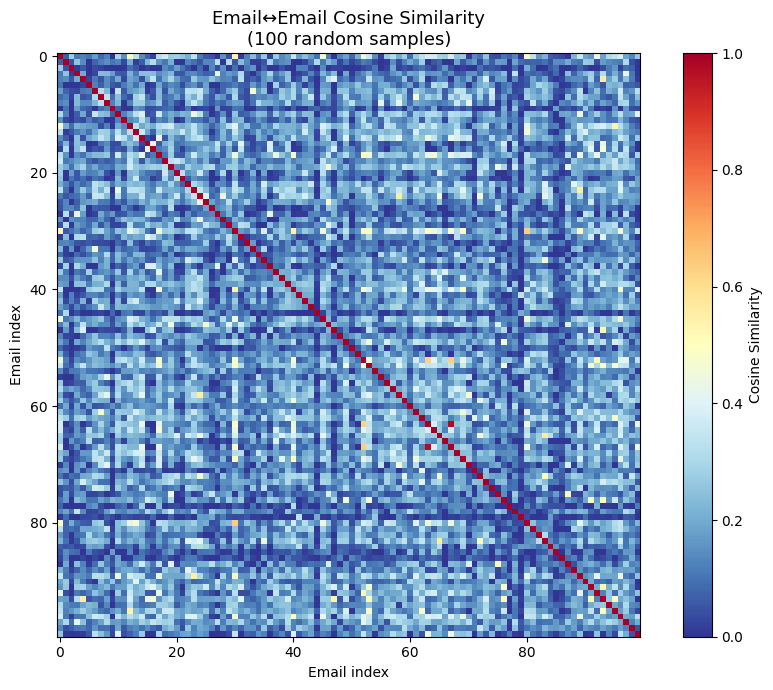

✅ Heatmap saved → email_similarity_heatmap.png


In [7]:
# How similar are emails to EACH OTHER? (cluster structure)
HEAT_N = 100
idx    = np.random.choice(len(df), HEAT_N, replace=False)

sub_email = email_sbert[idx]
sim_matrix = sub_email @ sub_email.T          # cosine sim (already L2-normed)

fig2, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(sim_matrix, cmap='RdYlBu_r', vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label='Cosine Similarity')
ax.set_title(f"Email↔Email Cosine Similarity\n({HEAT_N} random samples)", fontsize=13)
ax.set_xlabel("Email index")
ax.set_ylabel("Email index")
plt.tight_layout()
plt.savefig("email_similarity_heatmap.png", dpi=150)
plt.show()
print("✅ Heatmap saved → email_similarity_heatmap.png")

In [8]:
print("=" * 55)
print("   PART 3 COMPLETE — BIPARTITE GRAPH SUMMARY")
print("=" * 55)
print(f"  Full graph nodes      : {G.number_of_nodes():,}")
print(f"  Full graph edges      : {G.number_of_edges():,}")
print(f"  Graph density         : {nx.density(G):.6f}")
print(f"  Is valid bipartite    : {bipartite.is_bipartite(G)}")
print(f"  Avg edge cosine sim   : {np.mean(weights):.4f}")
print(f"  Pairs above threshold : {G.number_of_edges():,} / {len(df):,}")
print(f"\n  Files saved:")
print(f"    → bipartite_graph.html       (interactive)")
print(f"    → bipartite_analysis.png     (3-panel stats)")
print(f"    → email_similarity_heatmap.png")
print("=" * 55)

   PART 3 COMPLETE — BIPARTITE GRAPH SUMMARY
  Full graph nodes      : 96,368
  Full graph edges      : 29,321
  Graph density         : 0.000006
  Is valid bipartite    : True
  Avg edge cosine sim   : 0.5928
  Pairs above threshold : 29,321 / 48,184

  Files saved:
    → bipartite_graph.html       (interactive)
    → bipartite_analysis.png     (3-panel stats)
    → email_similarity_heatmap.png
